In [43]:
import itertools as it
import os
import warnings

import biom
from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd
import scipy
import seaborn as sn
import skbio
import statsmodels.formula.api as smf
import statsmodels.graphics as smg

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.diversity.actions as q2_div
# import qiime2.plugins.deicode.actions as q2_deicode
import qiime2.plugins.feature_table.actions as q2_feature_table
import qiime2.plugins.taxa.actions as q2_taxa

from scripts.arg_plotting import add_watermark, plot_strip
from scripts.arg_lme import fit_full_lme

rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)

# sn.set_palette(['#969696', '#009E73','#9D654C', 
                # '#97CE2F', '#098BD9',  '#CC79A7'])


%matplotlib inline

In [45]:
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
beta_metrics = ['jaccard', 'unweighted_unifrac',
                'rpca', 'phylo_rpca',
                 'braycurtis', 'weighted_unifrac',
               ]
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}

In [3]:
metadata_q2 = Metadata.load('final-data/01.metadata/analysis_sample_meta.tsv')
sample_meta = metadata_q2.to_dataframe()
metadata_q2 = metadata_q2.filter_ids(sample_meta.index.values)

In [4]:
track_step = pd.read_csv('final-data/01.metadata/track_all_samples.tsv',
                            sep='\t',
                            dtype=str)
track_step = \
    track_step.loc[track_step['sample-id'].isin(sample_meta.index)].copy()
track_step[['drop_count', 'drop_step']] = \
    track_step[['drop_count', 'drop_step']].astype(float).astype(int)
track_step['timepoint'] = track_step['timepoint'].astype(float)
track_step.set_index(['abx_code2', 'host_subject_id', 'sample-id'],
                     inplace=True)
track_step.replace({'marker': {'X': 'x'}}, inplace=True)
track_step.shape

(473, 9)

In [5]:
os.listdir(f'final-data/04.beta-diveristy/')

['braycurtis_1M_avg_dm.qza',
 'unweighted_unifrac_1M_avg_dm.qza',
 'unweighted_unifrac_1M_avg_from_baseline.qza',
 'braycurtis_1M_avg_from_baseline.qza',
 'jaccard_1M_avg_dm.qza',
 'jaccard_1M_avg_from_baseline.qza',
 'weighted_unifrac_1M_avg_dm.qza',
 'weighted_unifrac_1M_avg_from_baseline.qza']

In [6]:
dms_q2 = {
    fp.split('_1M')[0]: Artifact.load(f'final-data/04.beta-diveristy/{fp}')
    for fp in os.listdir(f'final-data/04.beta-diveristy/')
    if 'dm' in fp
}
dms_q2['rpca'] = Artifact.load('final-data/05.rpca/full_rpca/distance-matrix.qza')
dms_q2['phylo_rpca'] = Artifact.load('final-data/05.rpca/phylo_rpca/distance-matrix.qza')

In [7]:
dm_long = {
    metric: art.view(skbio.DistanceMatrix).filter(sample_meta.index)
    for metric, art in dms_q2.items()
}

dm_long = pd.DataFrame({
    metric: dm.to_series() for metric, dm in dm_long.items()
})
dm_long.index.set_names(['sample0', 'sample1'], inplace=True)
dm_long.reset_index(inplace=True)

dm_long['subject0'] = \
    sample_meta.loc[dm_long['sample0'], 'host_subject_id'].reset_index(drop=True)
dm_long['subject1'] = \
    sample_meta.loc[dm_long['sample1'], 'host_subject_id'].reset_index(drop=True)
dm_long['plate0'] = \
    sample_meta.loc[dm_long['sample0'], 'extraction_no'].reset_index(drop=True)
dm_long['plate1'] = \
    sample_meta.loc[dm_long['sample1'], 'extraction_no'].reset_index(drop=True)
dm_long['abx0'] = \
    sample_meta.loc[dm_long['sample0'], 'antibiotic'].reset_index(drop=True)
dm_long['abx1'] = \
    sample_meta.loc[dm_long['sample1'], 'antibiotic'].reset_index(drop=True)

In [8]:
dm_long['same_subject'] = dm_long['subject0'] == dm_long['subject1']
dm_long['same_plate'] = dm_long['plate0'] == dm_long['plate1']
dm_long['same_antibiotic'] = dm_long['abx0'] == dm_long['abx1']

In [9]:
dm_long['matched'] = dm_long[['same_plate', 'same_antibiotic']].all(axis=1)

In [10]:
dm_long.loc[dm_long['matched'], 'compare'] = 'between'
dm_long.loc[dm_long['same_subject'], 'compare'] = 'within'

In [11]:
dm_long.columns

Index(['sample0', 'sample1', 'braycurtis', 'unweighted_unifrac', 'jaccard',
       'weighted_unifrac', 'rpca', 'phylo_rpca', 'subject0', 'subject1',
       'plate0', 'plate1', 'abx0', 'abx1', 'same_subject', 'same_plate',
       'same_antibiotic', 'matched', 'compare'],
      dtype='object')

In [12]:
from scipy.stats import ttest_ind
def permutative_t_test(metric, grouper, data, nperm=999):
    """
    Performs a permutative t-test
    """
    summary = pd.DataFrame(
        data=np.vstack([
            np.random.permutation(data[metric]) for i in range(nperm)
        ]).T,
        index=data.index
    )
    summary['reference'] = data[metric]
    summary['group'] = data[grouper]
    summary.set_index('group', inplace=True)
    grouped = summary.groupby('group')
    
    t_stat = pd.Series({
        col: ttest_ind(*grouped[col].apply(lambda x: x.values).values, equal_var=False)[0]
        for col in summary.columns
    })
    ref_val = t_stat['reference']
    t_stat = t_stat * np.sign(ref_val)
    p_val = (t_stat >= ref_val * np.sign(ref_val)).mean()
    
    return ref_val, p_val, nperm

In [13]:
perm_summary = {
    metric: permutative_t_test(metric=metric, grouper='compare', data=dm_long)
    for metric in dms_q2.keys()
}
perm_summary

{'braycurtis': (47.27523539690254, 0.001, 999),
 'unweighted_unifrac': (38.9559588356948, 0.001, 999),
 'jaccard': (40.432139737510106, 0.001, 999),
 'weighted_unifrac': (21.446361011841507, 0.001, 999),
 'rpca': (29.244817154009567, 0.001, 999),
 'phylo_rpca': (29.390817001869003, 0.001, 999)}

In [31]:
uu_pcoa_q2, = q2_div.pcoa(dms_q2['unweighted_unifrac'], number_of_dimensions=3)
uu_pcoa = uu_pcoa_q2.view(skbio.OrdinationResults)

joint_coords = pd.concat(
    axis=1, objs=[sample_meta[['abx_code2', 'host_subject_id', 'timepoint']], 
                  uu_pcoa.samples[[0, 1]].add_prefix('pc')]
    )
joint_coords = joint_coords.loc[track_step.index.to_frame()['sample-id']].copy()
joint_coords['pc0'] = joint_coords['pc0'] * -1

In [35]:
coords_wide = joint_coords.pivot(index=['abx_code2', 'host_subject_id'],
                                columns='timepoint',
                                values=['pc0', 'pc1']
                                )

In [36]:
spacer = {0: '', 1: '\n', 2: '', 3: '\n', 4: '', 5:'\n'}
hide_axes = dict(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)
ax_in = dict(left=True, right=True, labelleft=False, labelright=False, labelsize=0, tickdir='in')

In [37]:
6 * 0.35

2.0999999999999996

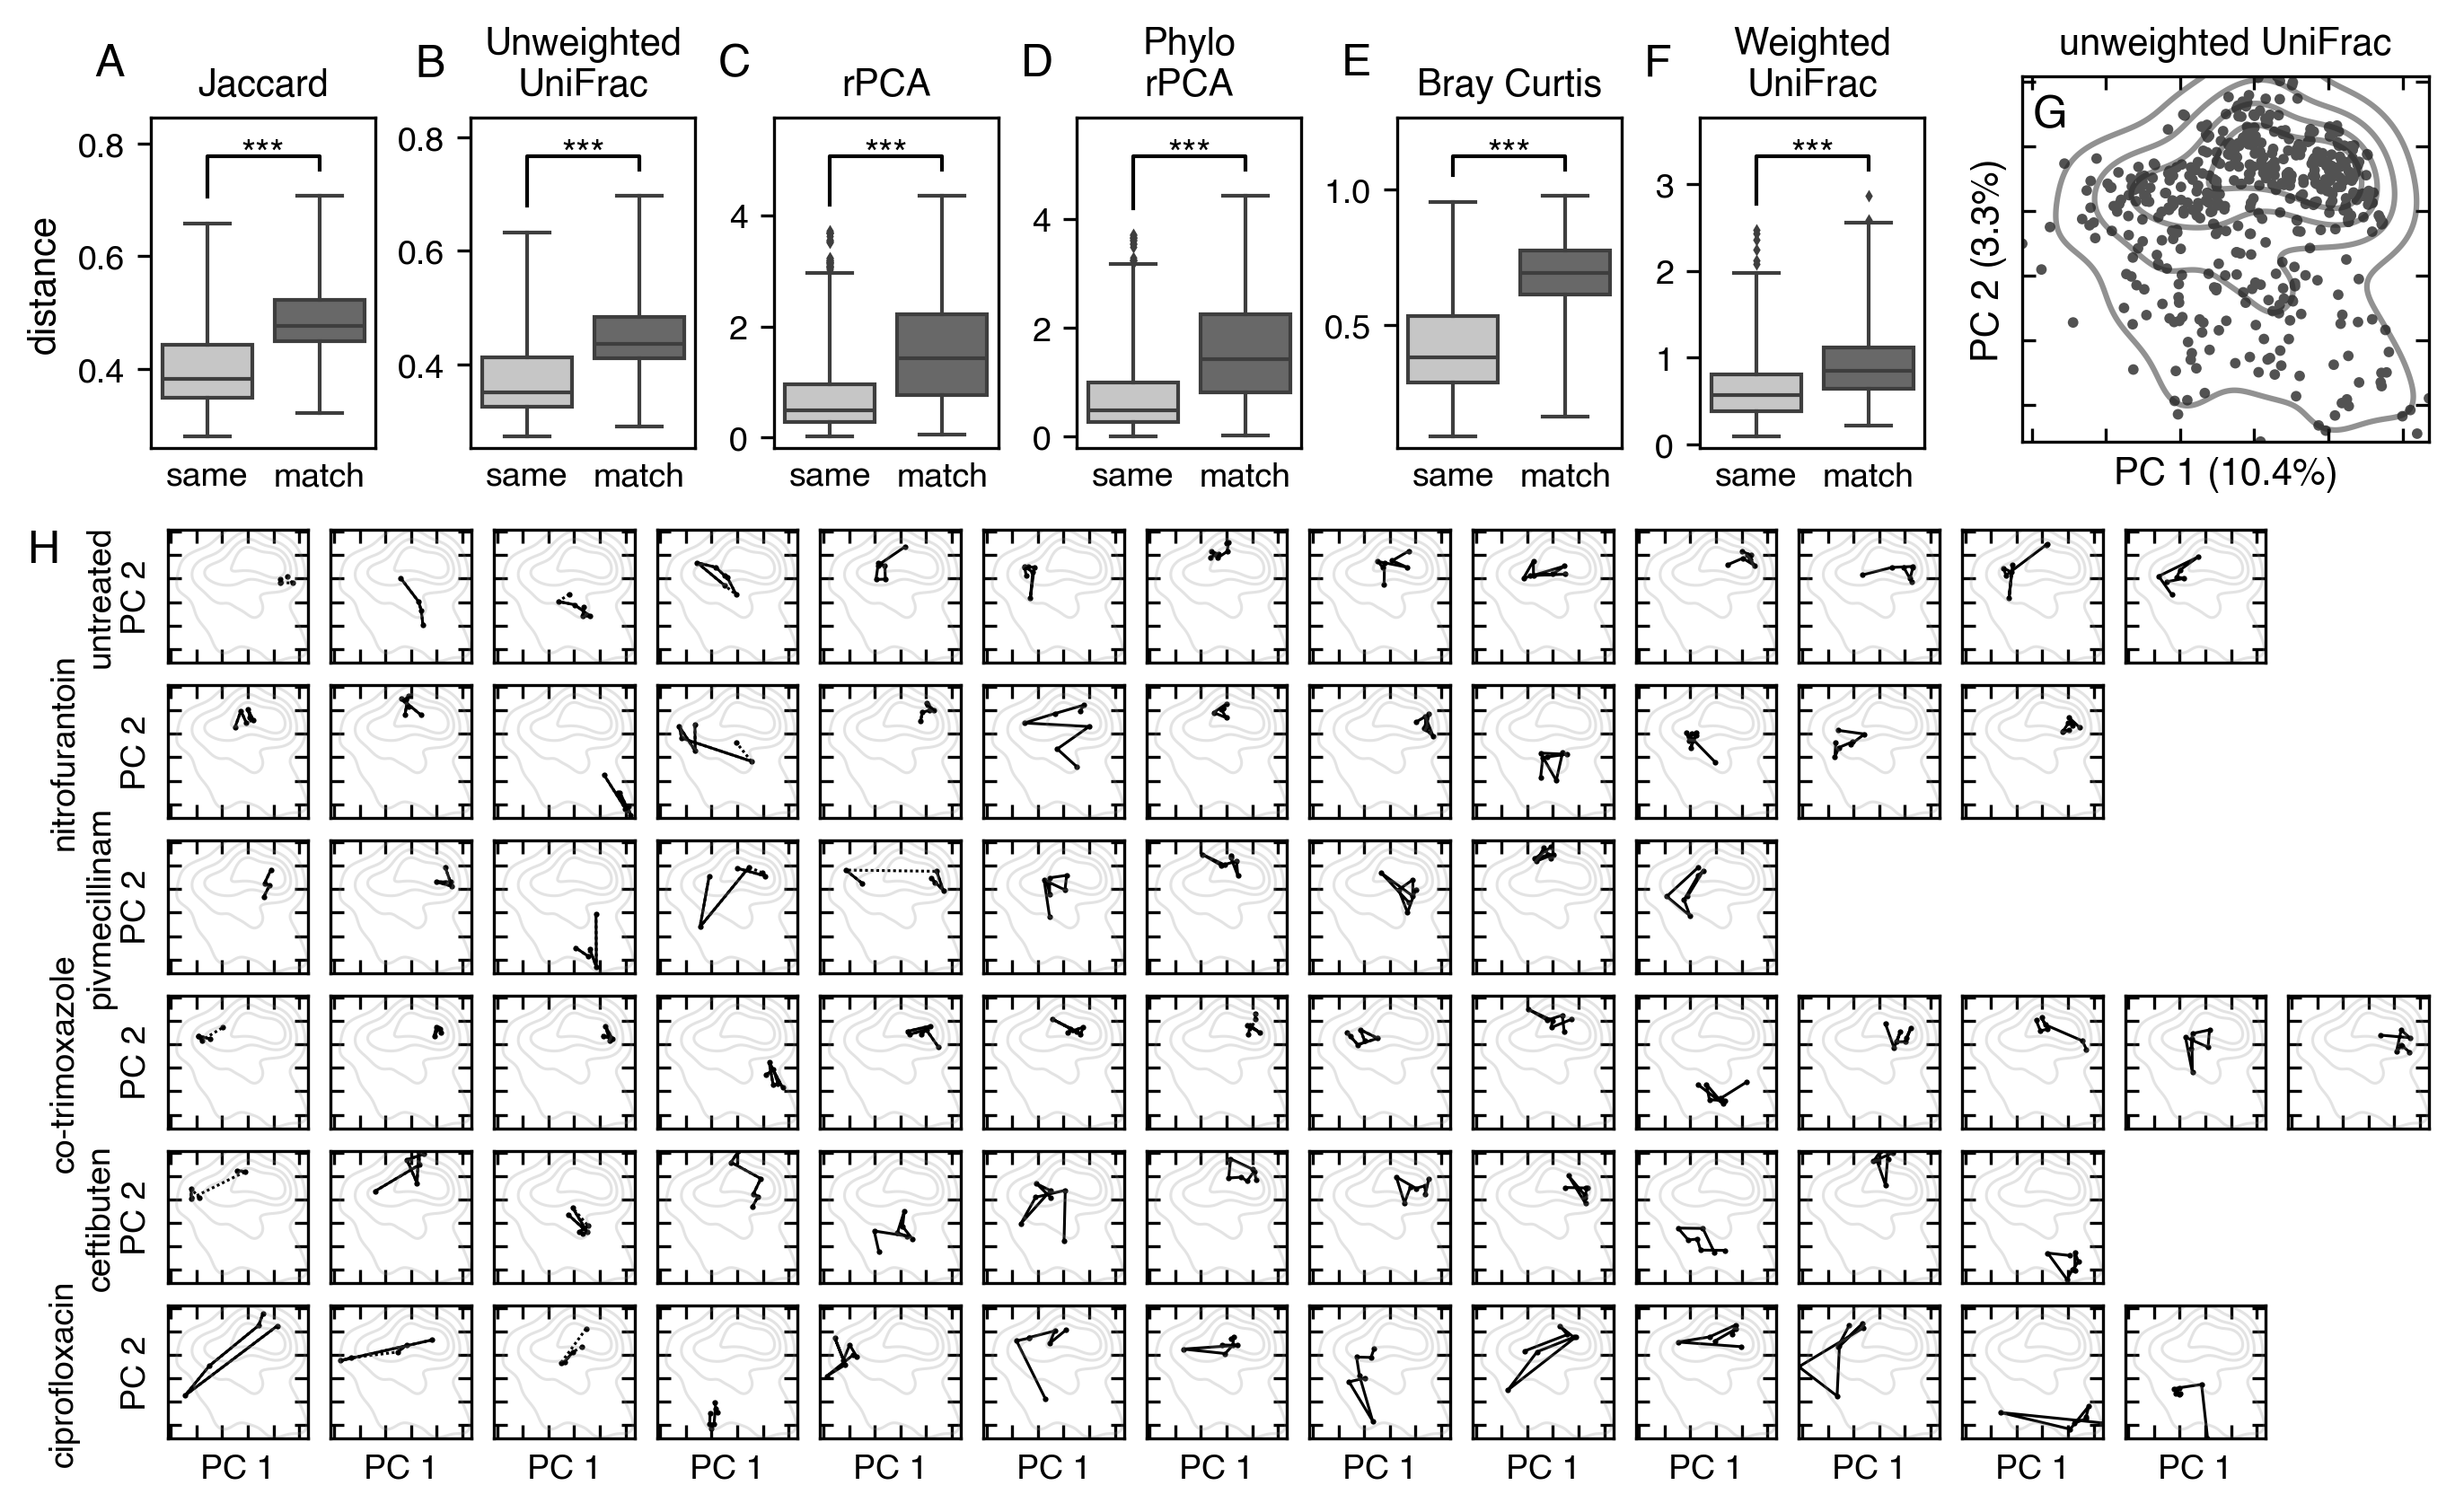

In [50]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(9, 5.5), 
                 facecolor='w')
fig_u, fig_l = fig.subfigures(2, 1, height_ratios=[0.35, 0.7])
fig_u_l, fig_u_r = fig_u.subfigures(1, 2, width_ratios=[0.8, 0.2])


# All sample PCoA Plot
ax_u_r = fig_u_r.add_subplot(1,1,1)
sn.kdeplot(x='pc0', y='pc1', data=joint_coords,
           cut=0,
           alpha=0.5,
           levels=5,
           linewidths=1.5,
           color='#252525',
           )
sn.scatterplot(x='pc0', y='pc1', 
               data=joint_coords,
               color='#525252',
               legend=False,
               ax=ax_u_r,
               s=8,
               edgecolor='None',
               )
ax_u_r.xaxis.set_tick_params(**ax_in)
ax_u_r.yaxis.set_tick_params(**ax_in)
ax_u_r.set_xlabel('PC 1 ({0:>4.1%})'.format(*uu_pcoa.proportion_explained))
ax_u_r.set_ylabel('PC 2 ({1:>4.1%})'.format(*uu_pcoa.proportion_explained))
ax_u_r.text(ax_u_r.get_xlim()[0] + np.diff(ax_u_r.get_xlim()) * 0.025,
            ax_u_r.get_ylim()[0] + np.diff(ax_u_r.get_ylim()) * 0.95,
            'G',
            size=12,
            ha='left',
            va='top',
           )
ax_u_r.set_title('unweighted UniFrac', size=10)
xlim = ax_u_r.get_xlim()
ylim = ax_u_r.get_ylim()

# Distance boxplots
gs_u_l = fig_u_l.add_gridspec(1, 6)
for i, (a, metric) in enumerate(zip(*(list("ABCDEF"), beta_metrics))):
    ax = fig_u_l.add_subplot(gs_u_l[i])
    p_val = perm_summary[metric][1]
    sn.boxplot(x='compare',
               y=metric,
               data=dm_long, 
               order=['within', 'between'],
               palette='Greys',
               whis=3,
               fliersize=1,
               linewidth=1,
               ax=ax,
               )
    tops = dm_long.groupby('compare')[metric].max()
    ydelta = np.diff(ax.get_ylim())
    ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[0] + ydelta * 1.25)
    ax.plot([0, 0, 1, 1], 
            [tops['within'] + 0.1 * ydelta, tops.max() + 0.15 * ydelta, 
             tops.max() + 0.15 * ydelta, tops['between'] + 0.1 * ydelta],
            linewidth=1,
            color='k',
            )
    ax.text(0.5, tops.max() + 0.15 * ydelta, 
            ''.join(['*'] * int(np.floor(-np.log10(p_val)))),
            ha='center',
            va='center'
            )
    ax.set_xticklabels(['same', 'match'], size=9)
    ax.xaxis.set_tick_params(bottom=False, labelbottom=True, labelsize=9, length=0)
    ax.xaxis.get_label().set_visible(False)
    ax.set_ylabel('distance')
    ax.yaxis.set_tick_params(labelsize=9)
    ax.yaxis.get_label().set_visible(i == 0)
    ax.set_title(metric.replace('_', '\n').replace('yc', 'y c').title(
                        ).replace('nif', 'niF').replace('Rpca', 'rPCA'), 
                 size=10)
    ax.text(-1, ax.get_ylim()[1] + np.diff(ax.get_ylim()) * 0.1, 
            a, ha='left', va='bottom', size=12)

gs_l = fig_l.add_gridspec(6, 14)
for abx, indvs in joint_coords.groupby('abx_code2', sort=False):
    for i, (indv_, coords) in enumerate(indvs.groupby('host_subject_id', sort=False)):
        ax = fig_l.add_subplot(gs_l[int(abx), i], sharex=ax_u_r, sharey=ax_u_r)
        ax.xaxis.set_tick_params(left=True, right=True, 
                                 labelleft=False, labelright=False, 
                                 tickdir='in')
        ax.yaxis.set_tick_params(left=True, right=True, labelleft=False, 
                                 labelright=False, tickdir='in')
        ax.set_xlabel('PC 1', size=9)
        ax.xaxis.get_label().set_visible(abx == 5)
        # ax.yaxis.
        
        if len(coords) < 7:
            ax.plot(coords['pc0'], 
                    coords['pc1'], 
                    linewidth=0.75, 
                    color='k',
                    # color=colors[int(abx)],
                    linestyle=(0, (1, 1)), 
                    )
        ax.plot(coords_wide.loc[(abx, indv_), 'pc0'],
                coords_wide.loc[(abx, indv_), 'pc1'],
                linewidth=0.75, 
                color='k',
                marker='o',
                markeredgecolor='None',
                markersize=1.5,
                )
        sn.kdeplot(x='pc0', y='pc1', 
                    data=joint_coords,
                   color='#919191',
                    # palette='Greys', 
                    alpha=0.25,
                   # gridsize=100,
                   levels=5,
                   linewidths=0.75,
                )
        if i == 0:
            ax.set_ylabel('{0}\n{1}PC 2'.format(abx_order[int(abx)], spacer[int(abx)]), size=9)
            if int(abx) == 0:
                ax.text(xlim[0] - np.diff(xlim),
                        ylim[1], 
                        'H', size=12, ha='left', va='top')
        ax.yaxis.get_label().set_visible(i == 0)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)


In [ ]:
os.makedirs('20240507_high_res_figures/pngs', exist_ok=True)
os.makedirs('20240507_high_res_figures/pdfs', exist_ok=True)

fig.savefig('20240507_high_res_figures/pngs/fig_s03_intraindividual.png', 
            dpi=600, facecolor='w')
fig.savefig('20240507_high_res_figures/pdfs/fig_s03_intraindividual.pdf', facecolor='None')